In [1]:
# ============================================================
# P0 — Outcome I: Planetary Regime
# Definición de muestras y clasificación conservadora SE/SN
# ============================================================
#Se eligieron planetas pequeños ya que en este régimen tiene sentido preguntarse la relación de la irradiación
#Definimos tres muestras para planetas pequeños: 
#1. Una muestra con todos los planetas pequeños 
#2. Una muestra con todos los planetas pequeños, detectados por tránsito 
#    (se eligió debido  que el método de tránsito ha demostrado una amplia -consistencia en la determinación de radios)
#3. Una muestra de KEPLER, para probar uniformidad 

import pandas as pd
import numpy as np

df = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")

# ----------------------------
# 1. Muestra general small planets
# ----------------------------

FULL_SMALL = df[
    df["pl_rade"].notna() &
    (df["pl_rade"] > 1.0) &
    (df["pl_rade"] < 4.0)
].copy()

TRANSIT_SMALL = FULL_SMALL[
    FULL_SMALL["discoverymethod"] == "Transit"
].copy()

KEPLER_SMALL = FULL_SMALL[
    FULL_SMALL["disc_facility"].str.contains("Kepler", case=False, na=False)
].copy()

# ----------------------------
# 2. Clasificación conservadora 
#En lugar de obligar a los planetas a pertenecer a una u otra clasificación, eliminamos el "borde"
#Se eliminan ambigüedades
# ----------------------------

def clasificar_regimen_conservador(r):
    if pd.isna(r):
        return np.nan
    elif (r > 1.0) and (r < 1.6):
        return "super_Earth"
    elif (r >= 1.6) and (r <= 2.0):
        return "valley_excluded"
    elif (r > 2.0) and (r < 4.0):
        return "sub_Neptune"
    else:
        return np.nan

for sample in [FULL_SMALL, TRANSIT_SMALL, KEPLER_SMALL]:
    sample["regimen_planetario"] = sample["pl_rade"].apply(
        clasificar_regimen_conservador
    )
    
    sample["sub_neptune_conservador"] = np.where(
        sample["regimen_planetario"] == "sub_Neptune", 1,
        np.where(sample["regimen_planetario"] == "super_Earth", 0, np.nan)
    )

# ----------------------------
# 3. Tabla resumen de muestras

# ----------------------------

def resumir_muestra(nombre, data):
    return {
        "muestra": nombre,
        "N_planetas": len(data),
        "N_sistemas": data["hostname"].nunique(),
        "N_super_Earth": (data["regimen_planetario"] == "super_Earth").sum(),
        "N_valley_excluded": (data["regimen_planetario"] == "valley_excluded").sum(),
        "N_sub_Neptune": (data["regimen_planetario"] == "sub_Neptune").sum(),
        "N_modelo_conservador": data["sub_neptune_conservador"].notna().sum(),
        "frac_sub_Neptune_conservador": data["sub_neptune_conservador"].mean()
    }

tabla_muestras_planetary_regime = pd.DataFrame([
    resumir_muestra("FULL_SMALL", FULL_SMALL),
    resumir_muestra("TRANSIT_SMALL", TRANSIT_SMALL),
    resumir_muestra("KEPLER_SMALL", KEPLER_SMALL)
]).round(4)

tabla_muestras_planetary_regime

,muestra,N_planetas,N_sistemas,N_super_Earth,N_valley_excluded,N_sub_Neptune,N_modelo_conservador,frac_sub_Neptune_conservador
0,FULL_SMALL,3592,2621,934,613,2045,2979,0.6865
1,TRANSIT_SMALL,3261,2423,873,568,1820,2693,0.6758
2,KEPLER_SMALL,2300,1694,659,424,1217,1876,0.6487


In [2]:
tabla_muestras_planetary_regime.to_csv(
    "../tables/tabla_muestras_planetary_regime.csv",
    index=False
)

FULL_SMALL.to_csv(
    "../data_processed/sample_planetary_regime_FULL_SMALL.csv",
    index=False
)

TRANSIT_SMALL.to_csv(
    "../data_processed/sample_planetary_regime_TRANSIT_SMALL.csv",
    index=False
)

KEPLER_SMALL.to_csv(
    "../data_processed/sample_planetary_regime_KEPLER_SMALL.csv",
    index=False
)

In [3]:
# ----------------------------
# 4. Missingness de variables clave
# ----------------------------

variables_clave_regime = [
    "st_mass",
    "st_met",
    "st_teff",
    "pl_orbper",
    "st_rad"
]

def missingness_muestra(nombre, data):
    tabla = pd.DataFrame({
        "variable": variables_clave_regime,
        "N_disponibles": [data[v].notna().sum() for v in variables_clave_regime],
        "N_faltantes": [data[v].isna().sum() for v in variables_clave_regime],
        "porcentaje_disponible": [
            100 * data[v].notna().mean()
            for v in variables_clave_regime
        ]
    })
    
    tabla["muestra"] = nombre
    return tabla

tabla_missingness_planetary_regime = pd.concat([
    missingness_muestra("FULL_SMALL", FULL_SMALL),
    missingness_muestra("TRANSIT_SMALL", TRANSIT_SMALL),
    missingness_muestra("KEPLER_SMALL", KEPLER_SMALL)
], ignore_index=True).round(2)

tabla_missingness_planetary_regime = tabla_missingness_planetary_regime[
    [
        "muestra",
        "variable",
        "N_disponibles",
        "N_faltantes",
        "porcentaje_disponible"
    ]
]

tabla_missingness_planetary_regime.to_csv(
    "../tables/missingness_planetary_regime.csv",
    index=False
)

tabla_missingness_planetary_regime

,muestra,variable,N_disponibles,N_faltantes,porcentaje_disponible
0,FULL_SMALL,st_mass,3592,0,100.00
1,FULL_SMALL,st_met,3359,233,93.51
2,FULL_SMALL,st_teff,3539,53,98.52
3,FULL_SMALL,pl_orbper,3545,47,98.69
4,FULL_SMALL,st_rad,3537,55,98.47
5,TRANSIT_SMALL,st_mass,3261,0,100.00
6,TRANSIT_SMALL,st_met,3116,145,95.55
7,TRANSIT_SMALL,st_teff,3261,0,100.00
8,TRANSIT_SMALL,pl_orbper,3261,0,100.00
9,TRANSIT_SMALL,st_rad,3261,0,100.00


In [4]:
# ----------------------------
# 5. Tabla maestra para Outcome I
# ----------------------------

sample_planetary_regime = FULL_SMALL.copy()

sample_planetary_regime["sample_FULL_SMALL"] = True
sample_planetary_regime["sample_TRANSIT_SMALL"] = (
    sample_planetary_regime["discoverymethod"] == "Transit"
)
sample_planetary_regime["sample_KEPLER_SMALL"] = (
    sample_planetary_regime["disc_facility"].str.contains("Kepler", case=False, na=False)
)

sample_planetary_regime.to_csv(
    "../data_processed/sample_planetary_regime.csv",
    index=False
)

sample_planetary_regime.shape

(3592, 49)

Para el análisis del régimen planetario se construyó una muestra de planetas pequeños con 1 < Rp < 4 R⊕. Además de la muestra completa, se definieron dos submuestras de robustez: planetas descubiertos por tránsito y planetas descubiertos por Kepler. Para el modelo principal se adoptó una clasificación conservadora, definiendo como supertierras los planetas con 1 < Rp < 1.6 R⊕ y como sub-Neptunos aquellos con 2 < Rp < 4 R⊕. Los planetas con 1.6 ≤ Rp ≤ 2.0 R⊕ fueron excluidos del modelo principal para evitar forzar objetos cercanos a la transición entre ambas poblaciones.

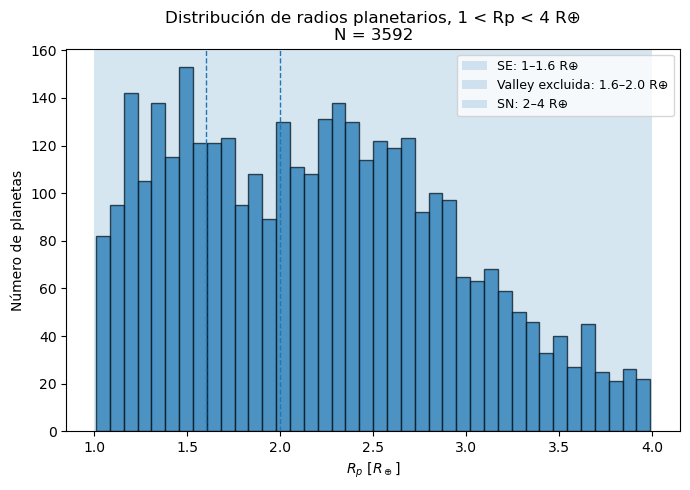

In [5]:
# ============================================================
# P1 — Figura A: distribución de radios en FULL_SMALL
# ============================================================

import matplotlib.pyplot as plt

df_figA = FULL_SMALL.copy()

N_total = len(df_figA)

plt.figure(figsize=(7, 5))

plt.hist(
    df_figA["pl_rade"],
    bins=40,
    density=False,
    alpha=0.75,
    edgecolor="black"
)

# Regiones
plt.axvspan(1.0, 1.6, alpha=0.18, label="SE: 1–1.6 R⊕")
plt.axvspan(1.6, 2.0, alpha=0.18, label="Valley excluida: 1.6–2.0 R⊕")
plt.axvspan(2.0, 4.0, alpha=0.18, label="SN: 2–4 R⊕")

# Líneas de corte
plt.axvline(1.6, linestyle="--", linewidth=1)
plt.axvline(2.0, linestyle="--", linewidth=1)

plt.xlabel(r"$R_p$ [$R_\oplus$]")
plt.ylabel("Número de planetas")
plt.title(f"Distribución de radios planetarios, 1 < Rp < 4 R⊕\nN = {N_total}")

plt.legend(fontsize=9)
plt.tight_layout()

plt.savefig(
    "../figures/P1_figura_A_distribucion_radios_regimen_planetario.png",
    dpi=300
)

plt.show()

In [6]:
# ============================================================
# Calcular irradiación para sample_planetary_regime
# ============================================================

T_sun = 5772  # K

# Periodo en años
sample_planetary_regime["P_years"] = (
    sample_planetary_regime["pl_orbper"] / 365.25
)

# Semieje mayor derivado con Kepler
sample_planetary_regime["a_kepler_au"] = (
    sample_planetary_regime["st_mass"] *
    sample_planetary_regime["P_years"]**2
)**(1/3)

# Usar semieje catalogado si existe; si no, Kepler
sample_planetary_regime["a_final_au"] = sample_planetary_regime["pl_orbsmax"]

sample_planetary_regime.loc[
    sample_planetary_regime["a_final_au"].isna(),
    "a_final_au"
] = sample_planetary_regime.loc[
    sample_planetary_regime["a_final_au"].isna(),
    "a_kepler_au"
]

sample_planetary_regime["a_origen"] = np.where(
    sample_planetary_regime["pl_orbsmax"].notna(),
    "catalogado",
    "kepler_derivado"
)

# Irradiación calculada
sample_planetary_regime["insol_calculada"] = (
    (sample_planetary_regime["st_rad"] ** 2) *
    (sample_planetary_regime["st_teff"] / T_sun) ** 4 *
    (1 / sample_planetary_regime["a_final_au"] ** 2)
)

sample_planetary_regime["log_insol_calculada"] = np.log10(
    sample_planetary_regime["insol_calculada"]
)

sample_planetary_regime[
    ["insol_calculada", "log_insol_calculada", "a_origen"]
].describe(include="all")

,insol_calculada,log_insol_calculada,a_origen
count,3536.000000,3536.000000,3592
unique,NaN,NaN,2
top,NaN,NaN,catalogado
freq,NaN,NaN,3291
mean,250.735041,1.774941,NaN
std,631.811896,0.807918,NaN
min,0.001643,-2.784362,NaN
25%,18.335769,1.263299,NaN
50%,68.242748,1.834055,NaN
75%,214.519848,2.331467,NaN


In [7]:
# ============================================================
# P1 — Figura B: fracción sub-Neptuno por irradiación
# con intervalos binomiales 95%
# ============================================================

from statsmodels.stats.proportion import proportion_confint

df_figB = sample_planetary_regime[
    sample_planetary_regime["sub_neptune_conservador"].notna() &
    sample_planetary_regime["log_insol_calculada"].notna()
].copy()

df_figB["insol_bin"] = pd.qcut(
    df_figB["log_insol_calculada"],
    q=4,
    labels=[
        "baja",
        "media-baja",
        "media-alta",
        "alta"
    ]
)

tabla_figB = (
    df_figB
    .groupby("insol_bin", observed=True)
    .agg(
        N=("sub_neptune_conservador", "count"),
        N_SN=("sub_neptune_conservador", "sum"),
        logF_min=("log_insol_calculada", "min"),
        logF_mediana=("log_insol_calculada", "median"),
        logF_max=("log_insol_calculada", "max"),
        f_SN=("sub_neptune_conservador", "mean")
    )
    .reset_index()
)

# Intervalos binomiales 95% tipo Wilson
ci_low = []
ci_high = []

for _, row in tabla_figB.iterrows():
    low, high = proportion_confint(
        count=row["N_SN"],
        nobs=row["N"],
        alpha=0.05,
        method="wilson"
    )
    ci_low.append(low)
    ci_high.append(high)

tabla_figB["IC95_low"] = ci_low
tabla_figB["IC95_high"] = ci_high

tabla_figB["error_low"] = tabla_figB["f_SN"] - tabla_figB["IC95_low"]
tabla_figB["error_high"] = tabla_figB["IC95_high"] - tabla_figB["f_SN"]

tabla_figB.to_csv(
    "../tables/P1_fraccion_sub_neptune_por_insolacion_IC95.csv",
    index=False
)

tabla_figB.round(4)

,insol_bin,N,N_SN,logF_min,logF_mediana,logF_max,f_SN,IC95_low,IC95_high,error_low,error_high
0,baja,734,576.0,-2.7844,0.8263,1.2571,0.7847,0.7536,0.8130,0.0312,0.0282
1,media-baja,733,589.0,1.2587,1.5607,1.8194,0.8035,0.7732,0.8307,0.0303,0.0271
2,media-alta,733,498.0,1.8205,2.0595,2.3157,0.6794,0.6448,0.7122,0.0346,0.0328
3,alta,734,348.0,2.3167,2.6170,4.0998,0.4741,0.4382,0.5103,0.0359,0.0362


Fracción conservadora de sub-Neptunos como función de la irradiación calculada. Se consideran supertierras los planetas con 1 < Rp < 1.6 R⊕ y sub-Neptunos aquellos con 2 < Rp < 4 R⊕; los planetas con 1.6 ≤ Rp ≤ 2.0 R⊕ se excluyen de esta comparación. Las barras de error muestran intervalos binomiales de confianza al 95%. La fracción de sub-Neptunos permanece alta en los dos bins de menor irradiación y disminuye claramente hacia irradiaciones mayores.

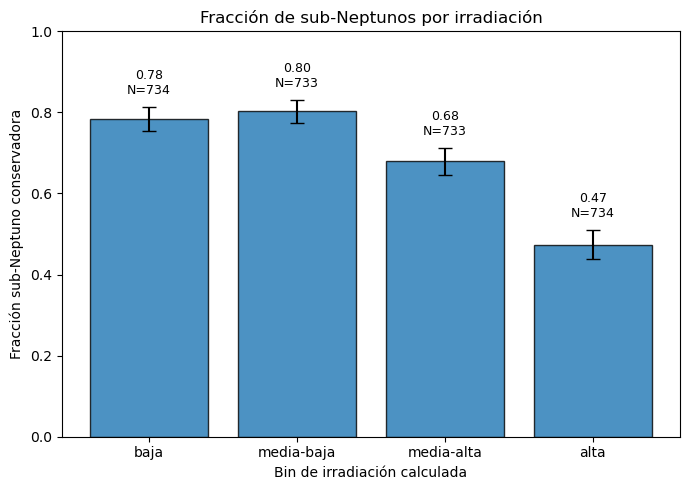

In [8]:
plt.figure(figsize=(7, 5))

plt.bar(
    tabla_figB["insol_bin"],
    tabla_figB["f_SN"],
    yerr=[
        tabla_figB["error_low"],
        tabla_figB["error_high"]
    ],
    capsize=5,
    edgecolor="black",
    alpha=0.8
)

plt.ylabel("Fracción sub-Neptuno conservadora")
plt.xlabel("Bin de irradiación calculada")
plt.title("Fracción de sub-Neptunos por irradiación")

plt.ylim(0, 1)

for i, row in tabla_figB.iterrows():
    plt.text(
        i,
        row["f_SN"] + row["error_high"] + 0.025,
        f"{row['f_SN']:.2f}\nN={int(row['N'])}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "../figures/P1_figura_B_fraccion_sub_neptune_insolacion_IC95.png",
    dpi=300
)

plt.show()

In [9]:
# ============================================================
# P2 — Modelo baseline M0
# logit P(SN) ~ logF
# ============================================================

import statsmodels.api as sm
from sklearn.metrics import log_loss, brier_score_loss

# Muestra para modelo conservador
df_M0 = sample_planetary_regime[
    sample_planetary_regime["sub_neptune_conservador"].notna() &
    sample_planetary_regime["log_insol_calculada"].notna()
].copy()

# Variable respuesta
y_M0 = df_M0["sub_neptune_conservador"]

# Predictor baseline
X_M0 = sm.add_constant(
    df_M0[["log_insol_calculada"]]
)

# Modelo
modelo_M0 = sm.Logit(y_M0, X_M0).fit()

# Predicciones
pred_M0 = modelo_M0.predict(X_M0)

# Tabla de coeficientes
params = modelo_M0.params
conf = modelo_M0.conf_int()
pvalues = modelo_M0.pvalues

tabla_coef_M0 = pd.DataFrame({
    "modelo": "M0",
    "variable": params.index,
    "coef": params.values,
    "IC95_coef_low": conf[0].values,
    "IC95_coef_high": conf[1].values,
    "OR": np.exp(params.values),
    "IC95_OR_low": np.exp(conf[0].values),
    "IC95_OR_high": np.exp(conf[1].values),
    "p_value": pvalues.values
}).round(4)

# Métricas globales
tabla_modelo_M0 = pd.DataFrame({
    "modelo": ["M0"],
    "formula": ["SN ~ logF"],
    "N": [int(modelo_M0.nobs)],
    "AIC": [modelo_M0.aic],
    "BIC": [modelo_M0.bic],
    "pseudo_R2": [modelo_M0.prsquared],
    "log_loss": [log_loss(y_M0, pred_M0)],
    "brier_score": [brier_score_loss(y_M0, pred_M0)]
}).round(4)

# Guardar
tabla_coef_M0.to_csv(
    "../tables/P2_M0_coeficientes_baseline_logF.csv",
    index=False
)

tabla_modelo_M0.to_csv(
    "../tables/P2_M0_metricas_baseline_logF.csv",
    index=False
)

tabla_coef_M0, tabla_modelo_M0

Optimization terminated successfully.
         Current function value: 0.588206
         Iterations 5


(  modelo             variable    coef  IC95_coef_low  IC95_coef_high      OR  \
 0     M0                const  2.1930         1.9619          2.4240  8.9617   
 1     M0  log_insol_calculada -0.7657        -0.8781         -0.6533  0.4650   
 
    IC95_OR_low  IC95_OR_high  p_value  
 0       7.1127       11.2912      0.0  
 1       0.4156        0.5203      0.0  ,
   modelo    formula     N        AIC        BIC  pseudo_R2  log_loss  \
 0     M0  SN ~ logF  2934  3455.5919  3467.5602     0.0554    0.5882   
 
    brier_score  
 0       0.1987  )

In [10]:
# ============================================================
# P3 — Modelo estelar principal M1
# Comparación justa M0 vs M1 en la misma muestra
# ============================================================

import statsmodels.api as sm
from sklearn.model_selection import GroupKFold
from sklearn.metrics import log_loss, brier_score_loss
from sklearn.linear_model import LogisticRegression

# ----------------------------
# 1. Muestra común para M0 y M1
# ----------------------------

df_M1 = sample_planetary_regime[
    sample_planetary_regime["sub_neptune_conservador"].notna() &
    sample_planetary_regime["log_insol_calculada"].notna() &
    sample_planetary_regime["st_mass"].notna() &
    sample_planetary_regime["st_met"].notna() &
    sample_planetary_regime["hostname"].notna()
].copy()

# Variables centradas
df_M1["logF_c"] = df_M1["log_insol_calculada"] - df_M1["log_insol_calculada"].mean()
df_M1["Mstar_c"] = df_M1["st_mass"] - df_M1["st_mass"].mean()
df_M1["FeH_c"] = df_M1["st_met"] - df_M1["st_met"].mean()

y = df_M1["sub_neptune_conservador"]
groups = df_M1["hostname"]

print("N planetas:", len(df_M1))
print("N sistemas:", df_M1["hostname"].nunique())
print("Fracción SN:", y.mean().round(4))

N planetas: 2775
N sistemas: 2097
Fracción SN: 0.6778


In [11]:
# ----------------------------
# 2. Modelos statsmodels con SE agrupado por hostname
# ----------------------------

# M0 común: solo irradiación
X0 = sm.add_constant(df_M1[["logF_c"]])

modelo_M0_common = sm.Logit(y, X0).fit(
    disp=False,
    cov_type="cluster",
    cov_kwds={"groups": df_M1["hostname"]}
)

# M1: irradiación + masa estelar + metalicidad
X1 = sm.add_constant(df_M1[["logF_c", "Mstar_c", "FeH_c"]])

modelo_M1 = sm.Logit(y, X1).fit(
    disp=False,
    cov_type="cluster",
    cov_kwds={"groups": df_M1["hostname"]}
)

modelo_M0_common.summary(), modelo_M1.summary()

(<class 'statsmodels.iolib.summary.Summary'>
 """
                               Logit Regression Results                             
 Dep. Variable:     sub_neptune_conservador   No. Observations:                 2775
 Model:                               Logit   Df Residuals:                     2773
 Method:                                MLE   Df Model:                            1
 Date:                     Fri, 21 Aug 2026   Pseudo R-squ.:                 0.06167
 Time:                             10:59:06   Log-Likelihood:                -1636.5
 converged:                            True   LL-Null:                       -1744.1
 Covariance Type:                   cluster   LLR p-value:                 1.051e-48
                  coef    std err          z      P>|z|      [0.025      0.975]
 ------------------------------------------------------------------------------
 const          0.8162      0.052     15.711      0.000       0.714       0.918
 logF_c        -0.8106      0.

In [12]:
# ----------------------------
# 3. OR físicamente interpretables
# ----------------------------

def tabla_or_fisica(modelo, modelo_nombre):
    params = modelo.params
    conf = modelo.conf_int()
    pvalues = modelo.pvalues
    
    filas = []
    
    if "logF_c" in params.index:
        escala = 1.0
        filas.append({
            "modelo": modelo_nombre,
            "predictor": "logF",
            "escala": "+1 dex en irradiación",
            "coef_escalado": params["logF_c"] * escala,
            "IC95_low_coef": conf.loc["logF_c", 0] * escala,
            "IC95_high_coef": conf.loc["logF_c", 1] * escala,
            "p_value": pvalues["logF_c"]
        })
    
    if "Mstar_c" in params.index:
        escala = 0.1
        filas.append({
            "modelo": modelo_nombre,
            "predictor": "Mstar",
            "escala": "+0.1 M_sun",
            "coef_escalado": params["Mstar_c"] * escala,
            "IC95_low_coef": conf.loc["Mstar_c", 0] * escala,
            "IC95_high_coef": conf.loc["Mstar_c", 1] * escala,
            "p_value": pvalues["Mstar_c"]
        })
    
    if "FeH_c" in params.index:
        escala = 0.1
        filas.append({
            "modelo": modelo_nombre,
            "predictor": "[Fe/H]",
            "escala": "+0.1 dex",
            "coef_escalado": params["FeH_c"] * escala,
            "IC95_low_coef": conf.loc["FeH_c", 0] * escala,
            "IC95_high_coef": conf.loc["FeH_c", 1] * escala,
            "p_value": pvalues["FeH_c"]
        })
    
    tabla = pd.DataFrame(filas)
    
    tabla["OR"] = np.exp(tabla["coef_escalado"])
    tabla["IC95_OR_low"] = np.exp(tabla["IC95_low_coef"])
    tabla["IC95_OR_high"] = np.exp(tabla["IC95_high_coef"])
    
    return tabla[
        [
            "modelo",
            "predictor",
            "escala",
            "OR",
            "IC95_OR_low",
            "IC95_OR_high",
            "p_value"
        ]
    ].round(4)

tabla_OR_M0 = tabla_or_fisica(modelo_M0_common, "M0_common")
tabla_OR_M1 = tabla_or_fisica(modelo_M1, "M1")

tabla_OR_P3 = pd.concat([tabla_OR_M0, tabla_OR_M1], ignore_index=True)

tabla_OR_P3.to_csv(
    "../tables/P3_OR_fisicos_M0_vs_M1.csv",
    index=False
)

tabla_OR_P3

,modelo,predictor,escala,OR,IC95_OR_low,IC95_OR_high,p_value
0,M0_common,logF,+1 dex en irradiación,0.4446,0.3806,0.5194,0.0000
1,M1,logF,+1 dex en irradiación,0.1795,0.1499,0.2150,0.0000
2,M1,Mstar,+0.1 M_sun,1.5871,1.4974,1.6822,0.0000
3,M1,[Fe/H],+0.1 dex,1.0781,1.0125,1.1479,0.0188


In [13]:
# ----------------------------
# 4. Métricas in-sample M0 vs M1
# ----------------------------

pred_M0_common = modelo_M0_common.predict(X0)
pred_M1 = modelo_M1.predict(X1)

tabla_metricas_P3 = pd.DataFrame({
    "modelo": ["M0_common", "M1"],
    "formula": [
        "SN ~ logF",
        "SN ~ logF + Mstar + [Fe/H]"
    ],
    "N": [
        int(modelo_M0_common.nobs),
        int(modelo_M1.nobs)
    ],
    "N_sistemas": [
        df_M1["hostname"].nunique(),
        df_M1["hostname"].nunique()
    ],
    "AIC": [
        modelo_M0_common.aic,
        modelo_M1.aic
    ],
    "BIC": [
        modelo_M0_common.bic,
        modelo_M1.bic
    ],
    "pseudo_R2": [
        modelo_M0_common.prsquared,
        modelo_M1.prsquared
    ],
    "log_loss_insample": [
        log_loss(y, pred_M0_common),
        log_loss(y, pred_M1)
    ],
    "brier_insample": [
        brier_score_loss(y, pred_M0_common),
        brier_score_loss(y, pred_M1)
    ]
})

tabla_metricas_P3["delta_AIC_vs_M0"] = (
    tabla_metricas_P3["AIC"] - tabla_metricas_P3.loc[0, "AIC"]
)

tabla_metricas_P3["delta_pseudo_R2_vs_M0"] = (
    tabla_metricas_P3["pseudo_R2"] - tabla_metricas_P3.loc[0, "pseudo_R2"]
)

tabla_metricas_P3 = tabla_metricas_P3.round(4)

tabla_metricas_P3.to_csv(
    "../tables/P3_metricas_insample_M0_vs_M1.csv",
    index=False
)

tabla_metricas_P3

,modelo,formula,N,N_sistemas,AIC,BIC,pseudo_R2,log_loss_insample,brier_insample,delta_AIC_vs_M0,delta_pseudo_R2_vs_M0
0,M0_common,SN ~ logF,2775,2097,3276.9944,3288.8512,0.0617,0.5897,0.1994,0.0000,0.0000
1,M1,SN ~ logF + Mstar + [Fe/H],2775,2097,2865.3114,2889.0250,0.1808,0.5148,0.1713,-411.6831,0.1192


In [14]:
# ----------------------------
# 5. 5-fold cross-validation agrupada por hostname
# ----------------------------

gkf = GroupKFold(n_splits=5)

features_M0 = ["logF_c"]
features_M1 = ["logF_c", "Mstar_c", "FeH_c"]

cv_rows = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(df_M1, y, groups=groups),
    start=1
):
    train = df_M1.iloc[train_idx].copy()
    test = df_M1.iloc[test_idx].copy()
    
    y_train = train["sub_neptune_conservador"]
    y_test = test["sub_neptune_conservador"]
    
    # Verificación: no compartir estrellas entre train y test
    overlap_hosts = set(train["hostname"]).intersection(set(test["hostname"]))
    assert len(overlap_hosts) == 0
    
    for modelo_nombre, features in [
        ("M0_common", features_M0),
        ("M1", features_M1)
    ]:
        clf = LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=1000
        )
        
        clf.fit(train[features], y_train)
        pred_test = clf.predict_proba(test[features])[:, 1]
        
        cv_rows.append({
            "fold": fold,
            "modelo": modelo_nombre,
            "N_train": len(train),
            "N_test": len(test),
            "N_hosts_train": train["hostname"].nunique(),
            "N_hosts_test": test["hostname"].nunique(),
            "test_log_loss": log_loss(y_test, pred_test),
            "test_brier": brier_score_loss(y_test, pred_test)
        })

tabla_cv_folds_P3 = pd.DataFrame(cv_rows).round(4)

tabla_cv_resumen_P3 = (
    tabla_cv_folds_P3
    .groupby("modelo")
    .agg(
        CV_logloss_mean=("test_log_loss", "mean"),
        CV_logloss_std=("test_log_loss", "std"),
        CV_brier_mean=("test_brier", "mean"),
        CV_brier_std=("test_brier", "std")
    )
    .reset_index()
)

# Delta respecto a M0_common
m0_logloss = tabla_cv_resumen_P3.loc[
    tabla_cv_resumen_P3["modelo"] == "M0_common",
    "CV_logloss_mean"
].iloc[0]

m0_brier = tabla_cv_resumen_P3.loc[
    tabla_cv_resumen_P3["modelo"] == "M0_common",
    "CV_brier_mean"
].iloc[0]

tabla_cv_resumen_P3["delta_CV_logloss_vs_M0"] = (
    tabla_cv_resumen_P3["CV_logloss_mean"] - m0_logloss
)

tabla_cv_resumen_P3["delta_CV_brier_vs_M0"] = (
    tabla_cv_resumen_P3["CV_brier_mean"] - m0_brier
)

tabla_cv_resumen_P3 = tabla_cv_resumen_P3.round(4)

tabla_cv_folds_P3.to_csv(
    "../tables/P3_CV_folds_grouped_by_hostname.csv",
    index=False
)

tabla_cv_resumen_P3.to_csv(
    "../tables/P3_CV_resumen_M0_vs_M1.csv",
    index=False
)

tabla_cv_resumen_P3

,modelo,CV_logloss_mean,CV_logloss_std,CV_brier_mean,CV_brier_std,delta_CV_logloss_vs_M0,delta_CV_brier_vs_M0
0,M0_common,0.5904,0.016,0.1996,0.0068,0.0000,0.0000
1,M1,0.5169,0.019,0.1720,0.0091,-0.0735,-0.0276


In [15]:
# ============================================================
# P4 — Modelo con interacción F x Mstar
# M2: SN ~ logF_c * Mstar_c + FeH_c
# Comparación contra M1
# ============================================================

from scipy.stats import chi2

# Usamos la misma muestra de P3
df_M2 = df_M1.copy()

# Interacción centrada
df_M2["logF_c_x_Mstar_c"] = df_M2["logF_c"] * df_M2["Mstar_c"]

y = df_M2["sub_neptune_conservador"]
groups = df_M2["hostname"]

# ----------------------------
# M1 en misma muestra
# ----------------------------

X1 = sm.add_constant(
    df_M2[["logF_c", "Mstar_c", "FeH_c"]]
)

modelo_M1_p4 = sm.Logit(y, X1).fit(
    disp=False,
    cov_type="cluster",
    cov_kwds={"groups": df_M2["hostname"]}
)

# ----------------------------
# M2 con interacción
# ----------------------------

X2 = sm.add_constant(
    df_M2[["logF_c", "Mstar_c", "FeH_c", "logF_c_x_Mstar_c"]]
)

modelo_M2 = sm.Logit(y, X2).fit(
    disp=False,
    cov_type="cluster",
    cov_kwds={"groups": df_M2["hostname"]}
)

modelo_M2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              Logit Regression Results                             
===================================================================================
Dep. Variable:     sub_neptune_conservador   No. Observations:                 2775
Model:                               Logit   Df Residuals:                     2770
Method:                                MLE   Df Model:                            4
Date:                     Fri, 21 Aug 2026   Pseudo R-squ.:                  0.1967
Time:                             10:59:06   Log-Likelihood:                -1401.0
converged:                            True   LL-Null:                       -1744.1
Covariance Type:                   cluster   LLR p-value:                3.605e-147
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                1.1619      0.063     18.336      0.000       1.038       1.286
logF_c              -1.8363      0.096    -19.216      0.000      -2.024      -1.649
Mstar_c              4.3754      0.284     15.427      0.000       3.820       4.931
FeH_c                0.9390      0.321      2.927      0.003       0.310       1.568
logF_c_x_Mstar_c    -1.4958      0.210     -7.119      0.000      -1.908      -1.084
====================================================================================
"""

In [16]:
# ============================================================
# P4 — Comparación in-sample M1 vs M2
# ============================================================

pred_M1_p4 = modelo_M1_p4.predict(X1)
pred_M2 = modelo_M2.predict(X2)

# Likelihood ratio test M1 vs M2
LR_stat = 2 * (modelo_M2.llf - modelo_M1_p4.llf)
LR_df = modelo_M2.df_model - modelo_M1_p4.df_model
LR_pvalue = chi2.sf(LR_stat, LR_df)

tabla_metricas_P4 = pd.DataFrame({
    "modelo": ["M1", "M2_interaccion"],
    "formula": [
        "SN ~ logF + Mstar + [Fe/H]",
        "SN ~ logF * Mstar + [Fe/H]"
    ],
    "N": [
        int(modelo_M1_p4.nobs),
        int(modelo_M2.nobs)
    ],
    "N_sistemas": [
        df_M2["hostname"].nunique(),
        df_M2["hostname"].nunique()
    ],
    "AIC": [
        modelo_M1_p4.aic,
        modelo_M2.aic
    ],
    "BIC": [
        modelo_M1_p4.bic,
        modelo_M2.bic
    ],
    "pseudo_R2": [
        modelo_M1_p4.prsquared,
        modelo_M2.prsquared
    ],
    "log_loss_insample": [
        log_loss(y, pred_M1_p4),
        log_loss(y, pred_M2)
    ],
    "brier_insample": [
        brier_score_loss(y, pred_M1_p4),
        brier_score_loss(y, pred_M2)
    ]
})

tabla_metricas_P4["delta_AIC_vs_M1"] = (
    tabla_metricas_P4["AIC"] - tabla_metricas_P4.loc[0, "AIC"]
)

tabla_metricas_P4["delta_BIC_vs_M1"] = (
    tabla_metricas_P4["BIC"] - tabla_metricas_P4.loc[0, "BIC"]
)

tabla_metricas_P4["delta_pseudo_R2_vs_M1"] = (
    tabla_metricas_P4["pseudo_R2"] - tabla_metricas_P4.loc[0, "pseudo_R2"]
)

tabla_metricas_P4["delta_log_loss_vs_M1"] = (
    tabla_metricas_P4["log_loss_insample"] - tabla_metricas_P4.loc[0, "log_loss_insample"]
)

tabla_metricas_P4["delta_brier_vs_M1"] = (
    tabla_metricas_P4["brier_insample"] - tabla_metricas_P4.loc[0, "brier_insample"]
)

tabla_metricas_P4 = tabla_metricas_P4.round(4)

tabla_LR_P4 = pd.DataFrame({
    "comparacion": ["M1_vs_M2"],
    "LR_stat": [LR_stat],
    "df": [LR_df],
    "p_value": [LR_pvalue]
}).round(6)

tabla_metricas_P4.to_csv(
    "../tables/P4_metricas_insample_M1_vs_M2.csv",
    index=False
)

tabla_LR_P4.to_csv(
    "../tables/P4_likelihood_ratio_M1_vs_M2.csv",
    index=False
)

tabla_metricas_P4, tabla_LR_P4

(           modelo                     formula     N  N_sistemas        AIC  \
 0              M1  SN ~ logF + Mstar + [Fe/H]  2775        2097  2865.3114   
 1  M2_interaccion  SN ~ logF * Mstar + [Fe/H]  2775        2097  2812.0342   
 
          BIC  pseudo_R2  log_loss_insample  brier_insample  delta_AIC_vs_M1  \
 0  2889.0250     0.1808             0.5148          0.1713           0.0000   
 1  2841.6762     0.1967             0.5049          0.1673         -53.2771   
 
    delta_BIC_vs_M1  delta_pseudo_R2_vs_M1  delta_log_loss_vs_M1  \
 0           0.0000                 0.0000                  0.00   
 1         -47.3487                 0.0158                 -0.01   
 
    delta_brier_vs_M1  
 0             0.0000  
 1            -0.0039  ,
   comparacion    LR_stat   df  p_value
 0    M1_vs_M2  55.277143  1.0      0.0)

In [17]:
# ============================================================
# P4 — 5-fold CV agrupada por hostname: M1 vs M2
# ============================================================

gkf = GroupKFold(n_splits=5)

features_M1 = ["logF_c", "Mstar_c", "FeH_c"]
features_M2 = ["logF_c", "Mstar_c", "FeH_c", "logF_c_x_Mstar_c"]

cv_rows_P4 = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(df_M2, y, groups=groups),
    start=1
):
    train = df_M2.iloc[train_idx].copy()
    test = df_M2.iloc[test_idx].copy()

    y_train = train["sub_neptune_conservador"]
    y_test = test["sub_neptune_conservador"]

    overlap_hosts = set(train["hostname"]).intersection(set(test["hostname"]))
    assert len(overlap_hosts) == 0

    for modelo_nombre, features in [
        ("M1", features_M1),
        ("M2_interaccion", features_M2)
    ]:
        clf = LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=1000
        )

        clf.fit(train[features], y_train)
        pred_test = clf.predict_proba(test[features])[:, 1]

        cv_rows_P4.append({
            "fold": fold,
            "modelo": modelo_nombre,
            "N_train": len(train),
            "N_test": len(test),
            "N_hosts_train": train["hostname"].nunique(),
            "N_hosts_test": test["hostname"].nunique(),
            "test_log_loss": log_loss(y_test, pred_test),
            "test_brier": brier_score_loss(y_test, pred_test)
        })

tabla_cv_folds_P4 = pd.DataFrame(cv_rows_P4).round(4)

tabla_cv_resumen_P4 = (
    tabla_cv_folds_P4
    .groupby("modelo")
    .agg(
        CV_logloss_mean=("test_log_loss", "mean"),
        CV_logloss_std=("test_log_loss", "std"),
        CV_brier_mean=("test_brier", "mean"),
        CV_brier_std=("test_brier", "std")
    )
    .reset_index()
)

m1_logloss = tabla_cv_resumen_P4.loc[
    tabla_cv_resumen_P4["modelo"] == "M1",
    "CV_logloss_mean"
].iloc[0]

m1_brier = tabla_cv_resumen_P4.loc[
    tabla_cv_resumen_P4["modelo"] == "M1",
    "CV_brier_mean"
].iloc[0]

tabla_cv_resumen_P4["delta_CV_logloss_vs_M1"] = (
    tabla_cv_resumen_P4["CV_logloss_mean"] - m1_logloss
)

tabla_cv_resumen_P4["delta_CV_brier_vs_M1"] = (
    tabla_cv_resumen_P4["CV_brier_mean"] - m1_brier
)

tabla_cv_resumen_P4 = tabla_cv_resumen_P4.round(4)

tabla_cv_folds_P4.to_csv(
    "../tables/P4_CV_folds_grouped_by_hostname_M1_vs_M2.csv",
    index=False
)

tabla_cv_resumen_P4.to_csv(
    "../tables/P4_CV_resumen_M1_vs_M2.csv",
    index=False
)

tabla_cv_resumen_P4

,modelo,CV_logloss_mean,CV_logloss_std,CV_brier_mean,CV_brier_std,delta_CV_logloss_vs_M1,delta_CV_brier_vs_M1
0,M1,0.5169,0.019,0.1720,0.0091,0.0000,0.0000
1,M2_interaccion,0.5071,0.018,0.1682,0.0088,-0.0098,-0.0038


In [18]:
# Reconstruir submuestras usando la tabla maestra ya enriquecida con irradiación

TRANSIT_SMALL_P5 = sample_planetary_regime[
    sample_planetary_regime["sample_TRANSIT_SMALL"] == True
].copy()

KEPLER_SMALL_P5 = sample_planetary_regime[
    sample_planetary_regime["sample_KEPLER_SMALL"] == True
].copy()

print("TRANSIT_SMALL_P5:", TRANSIT_SMALL_P5.shape)
print("KEPLER_SMALL_P5:", KEPLER_SMALL_P5.shape)

print("log_insol_calculada en TRANSIT:", "log_insol_calculada" in TRANSIT_SMALL_P5.columns)
print("log_insol_calculada en KEPLER:", "log_insol_calculada" in KEPLER_SMALL_P5.columns)

TRANSIT_SMALL_P5: (3261, 55)
KEPLER_SMALL_P5: (2300, 55)
log_insol_calculada en TRANSIT: True
log_insol_calculada en KEPLER: True


In [19]:
# ============================================================
# P5 — Robustez por submuestra: TRANSIT_SMALL y KEPLER_SMALL
# M1 vs M2 en cada submuestra
# ============================================================

from scipy.stats import chi2
from sklearn.model_selection import GroupKFold
from sklearn.metrics import log_loss, brier_score_loss
from sklearn.linear_model import LogisticRegression

def preparar_submuestra_para_modelos(data, nombre_muestra):
    temp = data[
        data["sub_neptune_conservador"].notna() &
        data["log_insol_calculada"].notna() &
        data["st_mass"].notna() &
        data["st_met"].notna() &
        data["hostname"].notna()
    ].copy()
    
    temp["logF_c"] = temp["log_insol_calculada"] - temp["log_insol_calculada"].mean()
    temp["Mstar_c"] = temp["st_mass"] - temp["st_mass"].mean()
    temp["FeH_c"] = temp["st_met"] - temp["st_met"].mean()
    temp["logF_c_x_Mstar_c"] = temp["logF_c"] * temp["Mstar_c"]
    temp["muestra"] = nombre_muestra
    
    return temp


def ajustar_M1_M2_submuestra(data, nombre_muestra):
    y = data["sub_neptune_conservador"]
    
    X1 = sm.add_constant(data[["logF_c", "Mstar_c", "FeH_c"]])
    X2 = sm.add_constant(data[["logF_c", "Mstar_c", "FeH_c", "logF_c_x_Mstar_c"]])
    
    modelo_M1_sub = sm.Logit(y, X1).fit(
        disp=False,
        cov_type="cluster",
        cov_kwds={"groups": data["hostname"]}
    )
    
    modelo_M2_sub = sm.Logit(y, X2).fit(
        disp=False,
        cov_type="cluster",
        cov_kwds={"groups": data["hostname"]}
    )
    
    LR_stat = 2 * (modelo_M2_sub.llf - modelo_M1_sub.llf)
    LR_df = modelo_M2_sub.df_model - modelo_M1_sub.df_model
    LR_pvalue = chi2.sf(LR_stat, LR_df)
    
    fila = {
        "muestra": nombre_muestra,
        "N": int(modelo_M2_sub.nobs),
        "N_sistemas": data["hostname"].nunique(),
        "coef_interaccion": modelo_M2_sub.params["logF_c_x_Mstar_c"],
        "IC95_low_interaccion": modelo_M2_sub.conf_int().loc["logF_c_x_Mstar_c", 0],
        "IC95_high_interaccion": modelo_M2_sub.conf_int().loc["logF_c_x_Mstar_c", 1],
        "p_interaccion": modelo_M2_sub.pvalues["logF_c_x_Mstar_c"],
        "AIC_M1": modelo_M1_sub.aic,
        "AIC_M2": modelo_M2_sub.aic,
        "delta_AIC_M2_vs_M1": modelo_M2_sub.aic - modelo_M1_sub.aic,
        "BIC_M1": modelo_M1_sub.bic,
        "BIC_M2": modelo_M2_sub.bic,
        "delta_BIC_M2_vs_M1": modelo_M2_sub.bic - modelo_M1_sub.bic,
        "pseudo_R2_M1": modelo_M1_sub.prsquared,
        "pseudo_R2_M2": modelo_M2_sub.prsquared,
        "delta_pseudo_R2": modelo_M2_sub.prsquared - modelo_M1_sub.prsquared,
        "LR_stat_M1_vs_M2": LR_stat,
        "LR_pvalue_M1_vs_M2": LR_pvalue
    }
    
    return modelo_M1_sub, modelo_M2_sub, fila


# Preparar submuestras
df_TRANSIT_P5 = preparar_submuestra_para_modelos(TRANSIT_SMALL_P5, "TRANSIT_SMALL")
df_KEPLER_P5 = preparar_submuestra_para_modelos(KEPLER_SMALL_P5, "KEPLER_SMALL")
# Ajustar modelos
modelo_M1_TRANSIT, modelo_M2_TRANSIT, fila_TRANSIT = ajustar_M1_M2_submuestra(
    df_TRANSIT_P5,
    "TRANSIT_SMALL"
)

modelo_M1_KEPLER, modelo_M2_KEPLER, fila_KEPLER = ajustar_M1_M2_submuestra(
    df_KEPLER_P5,
    "KEPLER_SMALL"
)

tabla_P5_robustez_insample = pd.DataFrame([
    fila_TRANSIT,
    fila_KEPLER
]).round(4)

tabla_P5_robustez_insample.to_csv(
    "../tables/P5_robustez_interaccion_TRANSIT_KEPLER_insample.csv",
    index=False
)

tabla_P5_robustez_insample

,muestra,N,N_sistemas,coef_interaccion,IC95_low_interaccion,IC95_high_interaccion,p_interaccion,AIC_M1,AIC_M2,delta_AIC_M2_vs_M1,BIC_M1,BIC_M2,delta_BIC_M2_vs_M1,pseudo_R2_M1,pseudo_R2_M2,delta_pseudo_R2,LR_stat_M1_vs_M2,LR_pvalue_M1_vs_M2
0,TRANSIT_SMALL,2565,1981,-1.5901,-2.1265,-1.0537,0.0,2682.5664,2642.3723,-40.1941,2705.9652,2671.6209,-34.3443,0.1785,0.1914,0.0130,42.1941,0.0
1,KEPLER_SMALL,1876,1455,-2.0175,-2.8696,-1.1654,0.0,1935.1634,1906.5527,-28.6107,1957.3110,1934.2372,-23.0738,0.2076,0.2202,0.0126,30.6107,0.0


El modelo con interacción entre irradiación y masa estelar mejora el ajuste respecto al modelo aditivo en la muestra completa y en las submuestras de robustez. El término de interacción mantiene signo negativo tanto en la muestra de planetas de tránsito como en la submuestra Kepler. En TRANSIT_SMALL, el coeficiente de interacción es -1.59, IC95% = [-2.13, -1.05], mientras que en KEPLER_SMALL es -2.02, IC95% = [-2.87, -1.17]. Además, el modelo con interacción reduce AIC y BIC en ambas submuestras. Esto sugiere que la asociación entre irradiación y régimen planetario no es independiente de la masa estelar.

In [20]:
# ============================================================
# P5 — Marginal effects / predicted probabilities
# P(SN | logF, Mstar) para Mstar P20, P50, P80
# con IC95%
# ============================================================

from scipy.special import expit

# Usamos df_M2 y modelo_M2 del P4
# M2: SN ~ logF_c + Mstar_c + FeH_c + logF_c_x_Mstar_c

# Valores representativos de masa estelar
mstar_vals = df_M2["st_mass"].quantile([0.20, 0.50, 0.80])

# Rango de irradiación observado, evitando extremos raros
logF_grid = np.linspace(
    df_M2["log_insol_calculada"].quantile(0.01),
    df_M2["log_insol_calculada"].quantile(0.99),
    200
)

# Metalicidad fija en la mediana
FeH_med = df_M2["st_met"].median()

# Medias usadas para centrar
logF_mean = df_M2["log_insol_calculada"].mean()
Mstar_mean = df_M2["st_mass"].mean()
FeH_mean = df_M2["st_met"].mean()

# Covarianza del modelo, usando los SE agrupados ya estimados
cov_M2 = modelo_M2.cov_params()
params_M2 = modelo_M2.params

pred_rows = []

for q, mstar in mstar_vals.items():
    
    for logF in logF_grid:
        
        logF_c = logF - logF_mean
        Mstar_c = mstar - Mstar_mean
        FeH_c = FeH_med - FeH_mean
        interaction = logF_c * Mstar_c
        
        x = pd.Series({
            "const": 1.0,
            "logF_c": logF_c,
            "Mstar_c": Mstar_c,
            "FeH_c": FeH_c,
            "logF_c_x_Mstar_c": interaction
        })
        
        # Asegurar mismo orden que el modelo
        x = x[params_M2.index]
        
        # Predicción en escala logit
        eta = np.dot(x, params_M2)
        
        # Error estándar de eta: sqrt(x' Cov x)
        se_eta = np.sqrt(np.dot(x, np.dot(cov_M2, x)))
        
        eta_low = eta - 1.96 * se_eta
        eta_high = eta + 1.96 * se_eta
        
        pred_rows.append({
            "percentil_Mstar": f"P{int(q*100)}",
            "Mstar": mstar,
            "logF": logF,
            "prob_SN": expit(eta),
            "IC95_low": expit(eta_low),
            "IC95_high": expit(eta_high)
        })

df_pred_P5 = pd.DataFrame(pred_rows)

df_pred_P5.to_csv(
    "../tables/P5_probabilidades_predichas_M2_marginal_effects.csv",
    index=False
)

df_pred_P5.head()

,percentil_Mstar,Mstar,logF,prob_SN,IC95_low,IC95_high
0,P20,0.7416,-0.273610,0.979112,0.969771,0.985609
1,P20,0.7416,-0.254817,0.978480,0.968960,0.985124
2,P20,0.7416,-0.236023,0.977828,0.968128,0.984623
3,P20,0.7416,-0.217230,0.977158,0.967274,0.984106
4,P20,0.7416,-0.198436,0.976468,0.966398,0.983571


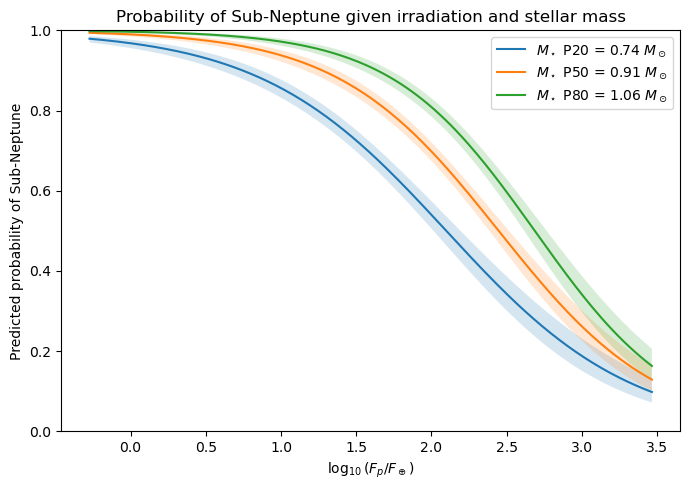

In [21]:
# ============================================================
# P5 — Figura: curvas predichas con IC95%
# ============================================================

plt.figure(figsize=(7, 5))

labels_limpios = {
    "P20": r"$M_\star$ P20",
    "P50": r"$M_\star$ P50",
    "P80": r"$M_\star$ P80"
}

for label, grupo in df_pred_P5.groupby("percentil_Mstar"):
    
    mstar_val = grupo["Mstar"].iloc[0]
    label_fig = f"{labels_limpios[label]} = {mstar_val:.2f} $M_\\odot$"
    
    plt.plot(
        grupo["logF"],
        grupo["prob_SN"],
        label=label_fig
    )
    
    plt.fill_between(
        grupo["logF"],
        grupo["IC95_low"],
        grupo["IC95_high"],
        alpha=0.18
    )

plt.xlabel(r"$\log_{10}(F_p/F_\oplus)$")
plt.ylabel("Predicted probability of Sub-Neptune")
plt.title("Probability of Sub-Neptune given irradiation and stellar mass")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../figures/P5_probabilidad_SN_vs_logF_por_Mstar_IC95.png",
    dpi=300
)

plt.show()

1. Para todas las masas estelares, la probabilidad de sub-Neptuno baja al aumentar la irradiación.

2. A irradiación fija, las estrellas más masivas mantienen mayor probabilidad predicha de sub-Neptuno.

3. La separación entre curvas es más visible en el régimen intermedio-alto de irradiación.

In [22]:
# ============================================================
# P5 — Tabla resumen en percentiles de irradiación
# ============================================================

logF_vals_resumen = df_M2["log_insol_calculada"].quantile([0.20, 0.50, 0.80])

resumen_rows = []

for qF, logF_target in logF_vals_resumen.items():
    for qM, mstar in mstar_vals.items():
        
        logF_c = logF_target - logF_mean
        Mstar_c = mstar - Mstar_mean
        FeH_c = FeH_med - FeH_mean
        interaction = logF_c * Mstar_c
        
        x = pd.Series({
            "const": 1.0,
            "logF_c": logF_c,
            "Mstar_c": Mstar_c,
            "FeH_c": FeH_c,
            "logF_c_x_Mstar_c": interaction
        })
        
        x = x[params_M2.index]
        
        eta = np.dot(x, params_M2)
        se_eta = np.sqrt(np.dot(x, np.dot(cov_M2, x)))
        
        resumen_rows.append({
            "percentil_logF": f"P{int(qF*100)}",
            "logF": logF_target,
            "percentil_Mstar": f"P{int(qM*100)}",
            "Mstar": mstar,
            "prob_SN": expit(eta),
            "IC95_low": expit(eta - 1.96 * se_eta),
            "IC95_high": expit(eta + 1.96 * se_eta)
        })

tabla_P5_probabilidades_representativas = pd.DataFrame(resumen_rows).round(4)

tabla_P5_probabilidades_representativas.to_csv(
    "../tables/P5_probabilidades_representativas_logF_Mstar.csv",
    index=False
)

tabla_P5_probabilidades_representativas

,percentil_logF,logF,percentil_Mstar,Mstar,prob_SN,IC95_low,IC95_high
0,P20,1.1182,P20,0.7416,0.8307,0.8058,0.8530
1,P20,1.1182,P50,0.9100,0.9235,0.9062,0.9378
2,P20,1.1182,P80,1.0600,0.9642,0.9526,0.9730
3,P50,1.8207,P20,0.7416,0.6110,0.5798,0.6414
4,P50,1.8207,P50,0.9100,0.7640,0.7410,0.7855
5,P50,1.8207,P80,1.0600,0.8604,0.8388,0.8796
6,P80,2.4176,P20,0.7416,0.3737,0.3329,0.4164
7,P80,2.4176,P50,0.9100,0.5141,0.4844,0.5437
8,P80,2.4176,P80,1.0600,0.6380,0.6065,0.6683


In [23]:
# ============================================================
# P7 — General radius classes
# Tabla descriptiva por clase de radio
# ============================================================

df_general_classes = df[
    df["clase_radio"].notna() &
    (df["clase_radio"] != "sin_dato")
].copy()

orden_clases_radio = [
    "terrestre",
    "supertierra",
    "neptuniano",
    "gigante_gaseoso",
    "mayor_que_jupiter"
]

tabla_general_radius_classes = (
    df_general_classes
    .groupby("clase_radio", observed=True)
    .agg(
        N_planetas=("pl_name", "count"),
        N_sistemas=("hostname", "nunique"),
        Rp_mediana=("pl_rade", "median"),
        Mstar_mediana=("st_mass", "median"),
        FeH_mediana=("st_met", "median"),
        periodo_mediana=("pl_orbper", "median"),
        masa_planetaria_mediana=("pl_bmasse", "median"),
        densidad_mediana=("densidad_calculada", "median")
    )
    .reset_index()
)

tabla_general_radius_classes["clase_radio"] = pd.Categorical(
    tabla_general_radius_classes["clase_radio"],
    categories=orden_clases_radio,
    ordered=True
)

tabla_general_radius_classes = (
    tabla_general_radius_classes
    .sort_values("clase_radio")
    .reset_index(drop=True)
    .round(4)
)

tabla_general_radius_classes.to_csv(
    "../tables/P7_tabla_general_radius_classes.csv",
    index=False
)

tabla_general_radius_classes

,clase_radio,N_planetas,N_sistemas,Rp_mediana,Mstar_mediana,FeH_mediana,periodo_mediana,masa_planetaria_mediana,densidad_mediana
0,terrestre,571,473,1.0470,0.8320,-0.02,4.5486,1.280,5.6162
1,supertierra,1188,1023,1.5900,0.8900,0.00,6.4525,3.290,4.4685
2,neptuniano,2374,1904,2.7200,0.9200,0.01,14.1552,8.200,2.2029
3,gigante_gaseoso,1853,1645,12.7000,1.0300,0.10,85.3316,411.272,1.0513
4,mayor_que_jupiter,237,235,16.8135,1.2995,0.05,3.3140,366.774,0.3873


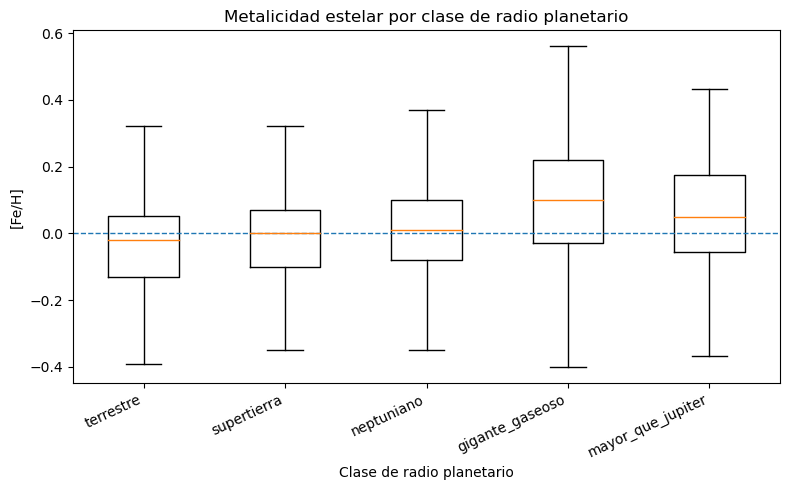

In [24]:
# ============================================================
# P7 — Figura: [Fe/H] por clase de radio
# ============================================================

df_feh_class = df_general_classes[
    df_general_classes["st_met"].notna()
].copy()

df_feh_class["clase_radio"] = pd.Categorical(
    df_feh_class["clase_radio"],
    categories=orden_clases_radio,
    ordered=True
)

plt.figure(figsize=(8, 5))

data_box = [
    df_feh_class.loc[
        df_feh_class["clase_radio"] == clase,
        "st_met"
    ].dropna()
    for clase in orden_clases_radio
]

plt.boxplot(
    data_box,
    labels=orden_clases_radio,
    showfliers=False
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.ylabel("[Fe/H]")
plt.xlabel("Clase de radio planetario")
plt.title("Metalicidad estelar por clase de radio planetario")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()

plt.savefig(
    "../figures/P7_feh_por_clase_radio.png",
    dpi=300
)

plt.show()

In [25]:
tabla_feh_por_clase_radio = (
    df_feh_class
    .groupby("clase_radio", observed=True)
    .agg(
        N=("st_met", "count"),
        FeH_mediana=("st_met", "median"),
        FeH_Q1=("st_met", lambda x: x.quantile(0.25)),
        FeH_Q3=("st_met", lambda x: x.quantile(0.75)),
        FeH_IQR=("st_met", lambda x: x.quantile(0.75) - x.quantile(0.25))
    )
    .reset_index()
    .round(4)
)

tabla_feh_por_clase_radio.to_csv(
    "../tables/P7_feh_por_clase_radio.csv",
    index=False
)

tabla_feh_por_clase_radio

,clase_radio,N,FeH_mediana,FeH_Q1,FeH_Q3,FeH_IQR
0,terrestre,543,-0.02,-0.130,0.0528,0.1828
1,supertierra,1138,0.00,-0.100,0.0700,0.1700
2,neptuniano,2160,0.01,-0.080,0.1000,0.1800
3,gigante_gaseoso,1538,0.10,-0.030,0.2200,0.2500
4,mayor_que_jupiter,221,0.05,-0.055,0.1760,0.2310


La caracterización general por clase de radio muestra diferencias en las propiedades típicas de los sistemas anfitriones. En particular, las clases de mayor radio, especialmente los gigantes gaseosos, aparecen alrededor de estrellas con metalicidades medianas más altas que las clases de menor radio. Este resultado se utiliza como contexto poblacional general; el análisis físico principal se restringe posteriormente a planetas pequeños con 1 < Rp < 4 R⊕ y a la distinción conservadora entre supertierras y sub-Neptunos.

NameError: name 'grid_sn' is not defined

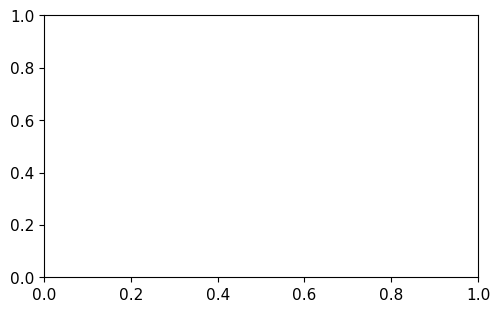

In [26]:
# ============================================================
# Poster-ready focused Outcome I figure
# P(sub-Neptune) vs irradiation by stellar mass
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path

figures = Path("../figures")
figures.mkdir(exist_ok=True)

# This assumes you already have grid_sn with:
# logF, pred_SN, pred_low, pred_high, Mstar_label
#
# If your prediction table has different names, adjust below.

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 14,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
})

fig, ax = plt.subplots(figsize=(5.6, 3.4))

for label in grid_sn["Mstar_label"].unique():
    subset = grid_sn[grid_sn["Mstar_label"] == label]

    ax.plot(
        subset["logF"],
        subset["pred_SN"],
        linewidth=2.6,
        label=label
    )

    ax.fill_between(
        subset["logF"],
        subset["pred_low"],
        subset["pred_high"],
        alpha=0.15
    )

ax.set_xlabel(r"$\log_{10}(F_p/F_\oplus)$")
ax.set_ylabel(r"Predicted $P(\mathrm{sub\!-\!Neptune})$")
ax.set_title("Small-planet regime: irradiation and stellar mass")

ax.legend(
    frameon=False,
    fontsize=9,
    loc="best"
)

ax.grid(alpha=0.18)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()

plt.savefig(
    figures / "OutcomeI_focused_SE_SN_zoom_poster.pdf",
    bbox_inches="tight"
)

plt.savefig(
    figures / "OutcomeI_focused_SE_SN_zoom_poster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# ============================================================
# Focused Outcome I — Poster-ready SE/SN zoom
# Self-contained version: rebuilds model + prediction grid
#
# Figure:
# P(sub-Neptune) vs irradiation for representative stellar masses
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.special import expit
from pathlib import Path

data_processed = Path("../data_processed")
figures = Path("../figures")
tables = Path("../tables")

figures.mkdir(exist_ok=True)
tables.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Load Outcome I sample
# ------------------------------------------------------------

sample_file = data_processed / "sample_planetary_regime.csv"

if sample_file.exists():
    df = pd.read_csv(sample_file)
else:
    df = pd.read_csv(data_processed / "03_catalogo_con_parametros_derivados.csv")

print("Loaded:", df.shape)

Loaded: (3592, 49)


In [28]:
# ============================================================
# Calculate incident flux if needed
# ============================================================

if "log_insol_calculada" not in df.columns:
    T_sun = 5772

    df["P_years"] = df["pl_orbper"] / 365.25

    df["a_kepler_au"] = (
        df["st_mass"] * df["P_years"]**2
    ) ** (1 / 3)

    df["a_final_au"] = df["pl_orbsmax"].copy()

    df.loc[
        df["a_final_au"].isna(),
        "a_final_au"
    ] = df.loc[
        df["a_final_au"].isna(),
        "a_kepler_au"
    ]

    df["insol_calculada"] = (
        df["st_rad"]**2
        * (df["st_teff"] / T_sun)**4
        / (df["a_final_au"]**2)
    )

    df["log_insol_calculada"] = np.log10(df["insol_calculada"])

print("Flux column ready.")

Flux column ready.


In [29]:
# ============================================================
# Conservative SE/SN classification
# 0 = super-Earth
# 1 = sub-Neptune
# exclude 1.6 <= Rp <= 2.0
# ============================================================

def clasificar_se_sn_conservador(r):
    if pd.isna(r):
        return np.nan
    elif (r > 1.0) and (r < 1.6):
        return 0
    elif (r > 2.0) and (r < 4.0):
        return 1
    else:
        return np.nan

if "sub_neptune_conservador" not in df.columns:
    df["sub_neptune_conservador"] = df["pl_rade"].apply(
        clasificar_se_sn_conservador
    )

df_sn = df[
    df["sub_neptune_conservador"].notna()
    & df["log_insol_calculada"].notna()
    & df["st_mass"].notna()
    & df["st_met"].notna()
    & df["hostname"].notna()
].copy()

df_sn["sub_neptune_conservador"] = df_sn[
    "sub_neptune_conservador"
].astype(int)

print("SE/SN model sample:", df_sn.shape)
print("Hosts:", df_sn["hostname"].nunique())
print(df_sn["sub_neptune_conservador"].value_counts())

SE/SN model sample: (2775, 54)
Hosts: 2097
sub_neptune_conservador
1    1881
0     894
Name: count, dtype: int64


In [30]:
# ============================================================
# Fit interaction model
#
# P(SN) ~ logF + Mstar + [Fe/H] + logF x Mstar
# ============================================================

logF_mean = df_sn["log_insol_calculada"].mean()
Mstar_mean = df_sn["st_mass"].mean()
FeH_mean = df_sn["st_met"].mean()

df_sn["logF_c"] = df_sn["log_insol_calculada"] - logF_mean
df_sn["Mstar_c"] = df_sn["st_mass"] - Mstar_mean
df_sn["FeH_c"] = df_sn["st_met"] - FeH_mean
df_sn["logF_x_Mstar"] = df_sn["logF_c"] * df_sn["Mstar_c"]

X = df_sn[
    [
        "logF_c",
        "Mstar_c",
        "FeH_c",
        "logF_x_Mstar"
    ]
].copy()

X = sm.add_constant(X, has_constant="add")

y = df_sn["sub_neptune_conservador"]

modelo_sn = sm.Logit(y, X).fit(disp=False)

print(modelo_sn.summary())

                              Logit Regression Results                             
Dep. Variable:     sub_neptune_conservador   No. Observations:                 2775
Model:                               Logit   Df Residuals:                     2770
Method:                                MLE   Df Model:                            4
Date:                     Fri, 21 Aug 2026   Pseudo R-squ.:                  0.1967
Time:                             11:00:52   Log-Likelihood:                -1401.0
converged:                            True   LL-Null:                       -1744.1
Covariance Type:                 nonrobust   LLR p-value:                3.605e-147
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            1.1619      0.057     20.230      0.000       1.049       1.274
logF_c          -1.8363      0.090    -20.334      0.000      -2.013      -1.659
Msta

In [31]:
# ============================================================
# Prediction grid for poster figure
# ============================================================

logF_grid = np.linspace(
    df_sn["log_insol_calculada"].quantile(0.02),
    df_sn["log_insol_calculada"].quantile(0.98),
    150
)

mstar_values = np.percentile(
    df_sn["st_mass"],
    [20, 50, 80]
)

mstar_labels = [
    rf"low $M_\star$ ({mstar_values[0]:.2f})",
    rf"median $M_\star$ ({mstar_values[1]:.2f})",
    rf"high $M_\star$ ({mstar_values[2]:.2f})"
]

FeH_fixed = df_sn["st_met"].median()

rows = []

for mstar, label in zip(mstar_values, mstar_labels):
    for logF in logF_grid:
        rows.append({
            "logF": logF,
            "st_mass": mstar,
            "st_met": FeH_fixed,
            "Mstar_label": label
        })

grid_sn = pd.DataFrame(rows)

grid_sn["logF_c"] = grid_sn["logF"] - logF_mean
grid_sn["Mstar_c"] = grid_sn["st_mass"] - Mstar_mean
grid_sn["FeH_c"] = grid_sn["st_met"] - FeH_mean
grid_sn["logF_x_Mstar"] = grid_sn["logF_c"] * grid_sn["Mstar_c"]

X_grid = grid_sn[
    [
        "logF_c",
        "Mstar_c",
        "FeH_c",
        "logF_x_Mstar"
    ]
].copy()

X_grid = sm.add_constant(X_grid, has_constant="add")

# Prediction + CI using delta method
params = modelo_sn.params.values
cov = modelo_sn.cov_params().values
X_mat = X_grid.values

eta = X_mat @ params
eta_se = np.sqrt(np.sum((X_mat @ cov) * X_mat, axis=1))

grid_sn["pred_SN"] = expit(eta)
grid_sn["pred_low"] = expit(eta - 1.96 * eta_se)
grid_sn["pred_high"] = expit(eta + 1.96 * eta_se)

grid_sn.to_csv(
    tables / "OutcomeI_focused_SE_SN_zoom_predictions.csv",
    index=False
)

grid_sn.head()

,logF,st_mass,st_met,Mstar_label,logF_c,Mstar_c,FeH_c,logF_x_Mstar,pred_SN,pred_low,pred_high
0,0.027905,0.7416,0.0,low $M_\star$ (0.74),-1.737933,-0.143638,0.007578,0.249633,0.966384,0.954929,0.975004
1,0.049979,0.7416,0.0,low $M_\star$ (0.74),-1.715859,-0.143638,0.007578,0.246463,0.965202,0.953518,0.974029
2,0.072052,0.7416,0.0,low $M_\star$ (0.74),-1.693786,-0.143638,0.007578,0.243292,0.963980,0.952064,0.973017
3,0.094126,0.7416,0.0,low $M_\star$ (0.74),-1.671712,-0.143638,0.007578,0.240122,0.962716,0.950567,0.971967
4,0.116199,0.7416,0.0,low $M_\star$ (0.74),-1.649639,-0.143638,0.007578,0.236951,0.961410,0.949026,0.970878


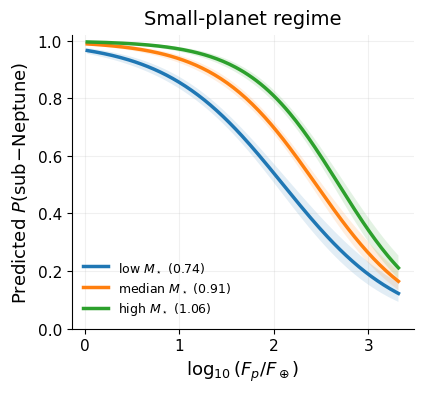

In [33]:
# ============================================================
# Poster-ready focused Outcome I figure
# Square-ish version for half-column layout
# ============================================================

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 9,
})

fig, ax = plt.subplots(figsize=(4.4, 4.1))

for label in grid_sn["Mstar_label"].unique():
    subset = grid_sn[grid_sn["Mstar_label"] == label]

    ax.plot(
        subset["logF"],
        subset["pred_SN"],
        linewidth=2.5,
        label=label
    )

    ax.fill_between(
        subset["logF"],
        subset["pred_low"],
        subset["pred_high"],
        alpha=0.13
    )

ax.set_xlabel(r"$\log_{10}(F_p/F_\oplus)$")
ax.set_ylabel(r"Predicted $P(\mathrm{sub\!-\!Neptune})$")
ax.set_title("Small-planet regime", pad=8)

# Give the y-axis visual room
ax.set_ylim(0, 1.02)

ax.legend(
    frameon=False,
    loc="lower left"
)

ax.grid(alpha=0.18)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    figures / "OutcomeI_focused_SE_SN_zoom_poster_square.pdf",
    bbox_inches="tight"
)

plt.savefig(
    figures / "OutcomeI_focused_SE_SN_zoom_poster_square.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()